**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**16 | Nested Training-Size GroupKFold: Random Forest vs Weighted CNN**

![Stage 16 scientific workflow](../../images/16_workflow.svg)

**Objective:** Compare 500- and 1,000-window-per-participant Train conditions across three subject-disjoint Development folds, using identical held-out windows for all models.

**Dataset:** The nested HARTH v2.0 Development cohorts: 14,201 base windows and 28,201 expanded windows from 29 participants, excluding reserved Test IDs S023 and S032.

**Notebook Scope:** Evaluate Random Forest and class-weighted CNN at both training sizes, retaining the base-500 Validation rows in every fold. This is exploratory Development cross-validation, not an independent final Test evaluation.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


**01. Imports and Reusable Research Utilities**

In [1]:
# ================ 01. Imports and Reusable Research Utilities ================

# ----------------------------- Standard Library ------------------------------
import sys
from pathlib import Path

# ---------------------- Data Analysis and Visualisation ----------------------
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

# -------------------- Deep Learning and Notebook Display ---------------------
import torch

from IPython.display import display

# ------------------------- Repository Configuration --------------------------
root = Path.cwd().resolve()

while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root: raise RuntimeError("Open from within the repository.")
    root = root.parent

# ----------------------- Shared and HARTH Source Paths -----------------------
sys.path.insert(0, str(root / "python_modules"))

sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------------- HARTH Nested Cohort Utilities -----------------------
from harth_data import HARTH_SUBJECTS, SENSOR_COLUMNS, ACTIVITY_NAMES, prepare_harth_nested_window_cohort

# ---------------------- Grouped Nested-Scale Evaluation ----------------------
from core.training_scale_cv import evaluate_nested_training_group_cv

from core.group_cross_validation import compare_models_by_subject

# ------------------------- PyTorch Environment Check -------------------------
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())


PyTorch: 2.12.1+cpu | CUDA: False


**02. Recreate Nested Development Window Cohorts**

Construct label-pure source windows separately for each participant. Every base-500 window remains in the expanded 1,000-cap cohort; out-of-task labels are excluded after segmentation, and S023 and S032 are not loaded.

In [2]:
# ============= 02. Recreate Strictly Nested Development Windows ==============

# ---------------- Reserved Test and Development Participants -----------------
RESERVED_TEST = {"S023", "S032"}

DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------------------ Documented Activity Classes ------------------------
TASK_CLASSES = tuple(range(1, 9))

# ---------------------- Strictly Nested Source Windows -----------------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,  # Include all original cap-500 windows in the larger cohort.
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------------- Development Cohort and Test Integrity -------------------
assert set(metadata["subject_id"]) == set(DEVELOPMENT_SUBJECTS)

assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# -------------------------- Original Cap-500 Cohort --------------------------
assert int(metadata["in_base_500"].sum()) == 14201

# --------------------------- Source Window Summary ---------------------------
display(overview)

print("Expanded signal windows:", X.shape)

print("Original base validation candidate windows:", int(metadata["in_base_500"].sum()))


Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343


,subject_id,eligible_windows,base_windows,expanded_windows,new_training_windows
0,S006,6708,500,1000,500
1,S008,7392,500,1000,500
2,S009,201,201,201,0
3,S010,6077,500,1000,500
4,S012,7309,500,1000,500
5,S013,6402,500,1000,500
6,S014,6299,500,1000,500
7,S015,7453,500,1000,500
8,S016,6272,500,1000,500
9,S017,6678,500,1000,500


Expanded signal windows: (28201, 6, 100)
Original base validation candidate windows: 14201


**03. Audit Eight-Class Activity Support**

Check participant-level coverage for the eight documented activity classes. The four model conditions share the same base-500 Validation windows within each fold; additional windows from held-out participants must not enter Train.

In [3]:
# =================== 03. Check Eight-Class Source Coverage ===================

# -------------------- Base and Expanded Activity Support ---------------------
counts = pd.DataFrame({
    "base": metadata.loc[metadata["in_base_500"], "label"].value_counts(),
    "expanded": metadata["label"].value_counts(),
}).reindex(TASK_CLASSES).fillna(0).astype(int)

# ------------------------- Documented Activity Names -------------------------
counts.index = [ACTIVITY_NAMES[code] for code in TASK_CLASSES]

# ------------------------- Additional Window Counts --------------------------
counts["additional"] = counts["expanded"] - counts["base"]

# --------------------------- Nested Task Coverage ----------------------------
display(counts)

assert (counts["base"] > 0).all()

assert (counts["additional"] >= 0).all()


,base,expanded,additional
Walking,3591,7101,3510
Running,1028,2050,1022
Shuffling,219,423,204
Stairs ascending,192,372,180
Stairs descending,182,355,173
Standing,2227,4380,2153
Sitting,5599,11196,5597
Lying,1163,2324,1161


**04. Fit Four Conditions Across Three Group Folds**

Within each participant-disjoint fold, fit RF 500, RF 1000, weighted CNN 500 and weighted CNN 1000. CNN scaling and class weights use fold Train only. Both CNN sizes use five epochs, which does not equalise the number of optimiser updates. The experiment therefore involves six CNN fits across three folds.

In [4]:
# =============== 04. Fit Four Conditions in Three Group Folds ================

# -------------------- Subject-Disjoint Fold Configuration --------------------
FOLDS = 3

# ---------------------------- CNN Training Budget ----------------------------
EPOCHS = 5

# --------------------- Matched Four-Condition GroupKFold ---------------------
fold_results, subject_results, class_results, prediction_records = evaluate_nested_training_group_cv(
    windows=X,
    metadata=metadata,
    classes=TASK_CLASSES,
    channel_names=SENSOR_COLUMNS,
    n_splits=FOLDS,
    epochs=EPOCHS,
    batch_size=128,
    learning_rate=1e-3,
    random_state=42,
    device="cuda" if torch.cuda.is_available() else "cpu",
    forbidden_subject_ids=RESERVED_TEST,  # Protect original reserved Test participants.
)

# --------------------- Validation Fold and Model Results ---------------------
display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "train_windows", "validation_windows", "macro_f1", "balanced_accuracy",
]].round(4))


Input windows: (28201, 6, 100)
Feature matrix: (28201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Fold 1/3: 19 Train people, 10 Validation people; 9201 vs 18201 Train windows
Fold 1: fitting Weighted CNN 500
Epoch 1/5 | loss=1.0101 | validation Macro F1=0.5766
Epoch 2/5 | loss=0.5557 | validation Macro F1=0.6125
Epoch 3/5 | loss=0.4243 | validation Macro F1=0.7211
Epoch 4/5 | loss=0.3267 | validation Macro F1=0.7528
Epoch 5/5 | loss=0.2661 | validation Macro F1=0.7268
Fold 1: fitting Weighted CNN 1000
Epoch 1/5 | loss=0.7780 | validation Macro F1=0.6784
Epoch 2/5 | loss=0.3817 | validation Macro F1=0.7440
Epoch 3/5 | loss=0.2573 | validation Macro F1=0.7835
Epoch 4/5 | loss=0.2031 | validation Macro F1=0.7429
Epoch 5/5 | loss=0.1794 | validation Macro F1=0.7609
Fold 2/3: 19 Train people, 10 Validation people; 9500 vs 19000 Train windows
Fold 2: fitting Weighted CNN 500
Epoch 1/5 | loss=0.9811 | validation Macro F1=0.5874
Epoch 2/5 | loss=0.5193 | validation Macro F1=0

,fold,model,train_subjects,validation_subjects,train_windows,validation_windows,macro_f1,balanced_accuracy
0,1,RF 500,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,0.7981,0.8346
1,1,RF 1000,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",18201,5000,0.7839,0.8316
2,1,Weighted CNN 500,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,0.7268,0.8197
3,1,Weighted CNN 1000,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",18201,5000,0.7609,0.8464
4,2,RF 500,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,0.7634,0.7584
5,2,RF 1000,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",19000,4701,0.7862,0.7785
6,2,Weighted CNN 500,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,0.7963,0.7787
7,2,Weighted CNN 1000,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",19000,4701,0.8066,0.8442
8,3,RF 500,"S006, S009, S010, S012, S014, S015, S017, S018...","S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,0.8613,0.8180
9,3,RF 1000,"S006, S009, S010, S012, S014, S015, S017, S018...","S008, S013, S016, S019, S022, S026, S029, S033...",19201,4500,0.8589,0.8152


**05. Compare Fold-Level Macro F1**

Recorded three-fold mean Macro F1 was 0.8076 (RF 500), 0.8097 (RF 1000), 0.7834 (weighted CNN 500) and 0.7962 (weighted CNN 1000). These are descriptive Development estimates, not independent Test scores.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,RF 1000,0.8097,0.0427,0.8084
1,RF 500,0.8076,0.0496,0.8037
2,Weighted CNN 1000,0.7962,0.0314,0.8276
3,Weighted CNN 500,0.7834,0.0514,0.8053


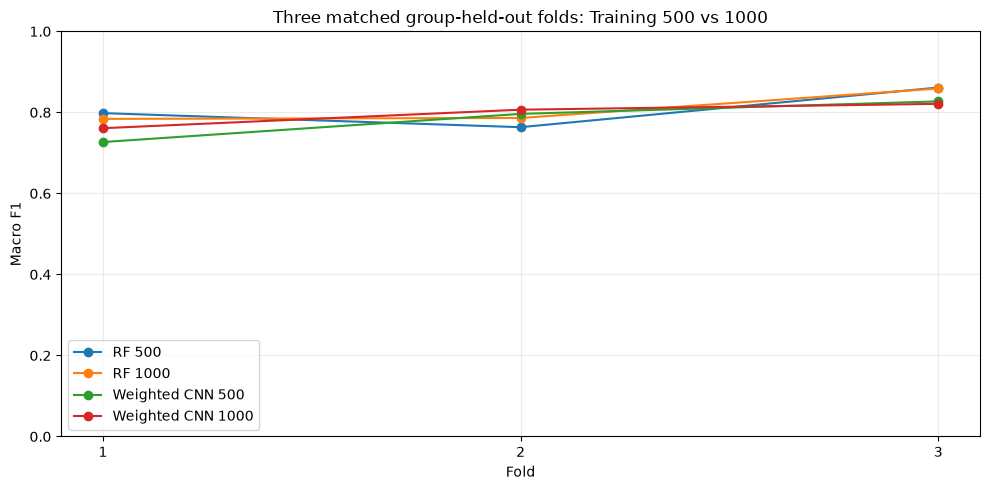

In [5]:
# ================= 05. Compare Fold-Level Validation Results =================

# ------------------------- Fold-Level Model Summary --------------------------
summary = fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
)

display(summary.round(4))

# --------------------- Matched Fold Macro F1 Comparison ----------------------
fig, ax = plt.subplots(figsize=(10, 5))

for name, table in fold_results.groupby("model", sort=False):
    ax.plot(table["fold"], table["macro_f1"], marker="o", label=name)

ax.set(title="Three matched group-held-out folds: Training 500 vs 1000",
       xlabel="Fold", ylabel="Macro F1", ylim=(0, 1),
       xticks=list(range(1, FOLDS + 1)))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


**06. Inspect Out-of-Fold Class Results**

Compare pooled class-specific performance on the same 14,201 base-500 held-out windows for each model. Shuffling and stair activities require separate inspection; overlapping windows are not independent participants.

,model,activity,support,precision,recall,f1
0,RF 500,Walking,3591,0.9265,0.9518,0.9390
1,RF 500,Running,1028,0.9836,0.9903,0.9869
2,RF 500,Shuffling,219,0.4694,0.5251,0.4957
3,RF 500,Stairs ascending,192,0.7447,0.5469,0.6306
4,RF 500,Stairs descending,182,0.7063,0.4890,0.5779
5,RF 500,Standing,2227,0.9378,0.9614,0.9494
6,RF 500,Sitting,5599,0.9967,0.9791,0.9878
7,RF 500,Lying,1163,0.9831,0.9991,0.9910
8,RF 1000,Walking,3591,0.9264,0.9457,0.9359
9,RF 1000,Running,1028,0.9826,0.9912,0.9869


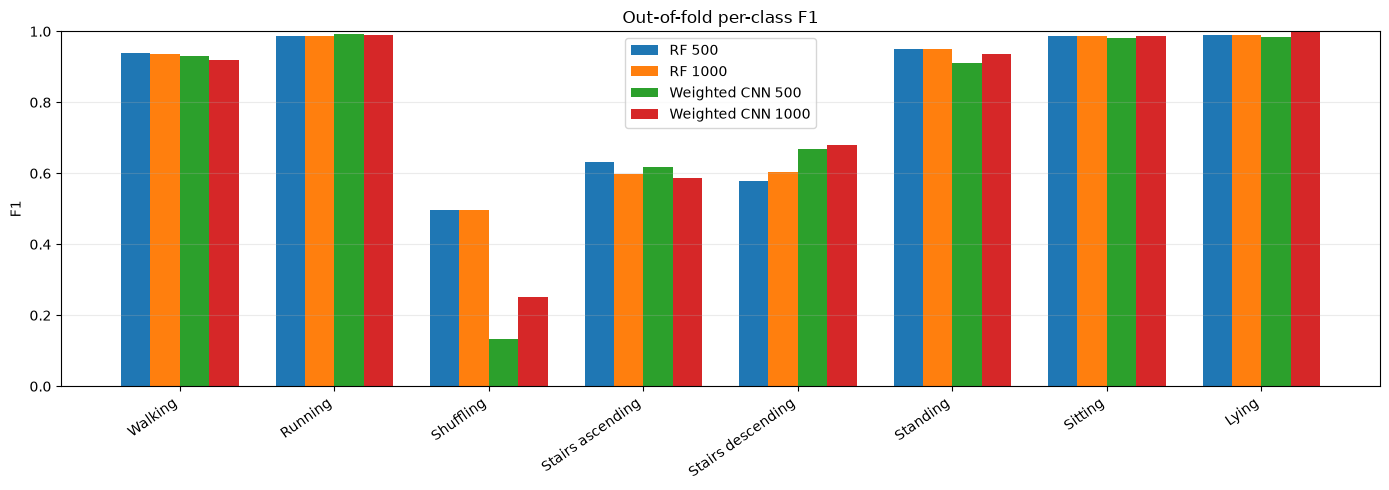

In [6]:
# ================= 06. Inspect Out-of-Fold Class Performance =================

# ------------------ Source Activity Names and Class Results ------------------
class_results["activity"] = class_results["class"].map(
    lambda code: ACTIVITY_NAMES[int(code)]
)

display(class_results[[
    "model", "activity", "support", "precision", "recall", "f1"
]].round(4))

# --------------------- Class-Wise Performance Comparison ---------------------
fig, ax = plt.subplots(figsize=(14, 5))

# ------------------------ Fixed Model Condition Order ------------------------
names = ["RF 500", "RF 1000", "Weighted CNN 500", "Weighted CNN 1000"]

positions = np.arange(len(TASK_CLASSES))

width = 0.19

# -------------------------- Pooled Activity F1 Plot --------------------------
for i, name in enumerate(names):
    score = class_results.loc[class_results["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 1.5)*width, score, width=width, label=name)

ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
              rotation=35, ha="right")
ax.set(title="Out-of-fold per-class F1", ylabel="F1", ylim=(0, 1))
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


**07. Compare Paired Results for 29 Participants**

Use fixed-task Macro F1 per held-out participant. RF 1000 scored higher for 15 participants, lower for 12 and tied for two relative to RF 500. Weighted CNN 1000 scored higher for 21 and lower for eight relative to weighted CNN 500. These comparisons are descriptive.

,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,RF 1000,RF 500,macro_f1_fixed_task,29,0.0091,0.0001,15,12,2


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN 1000,Weighted CNN 500,macro_f1_fixed_task,29,0.0155,0.0149,21,8,0


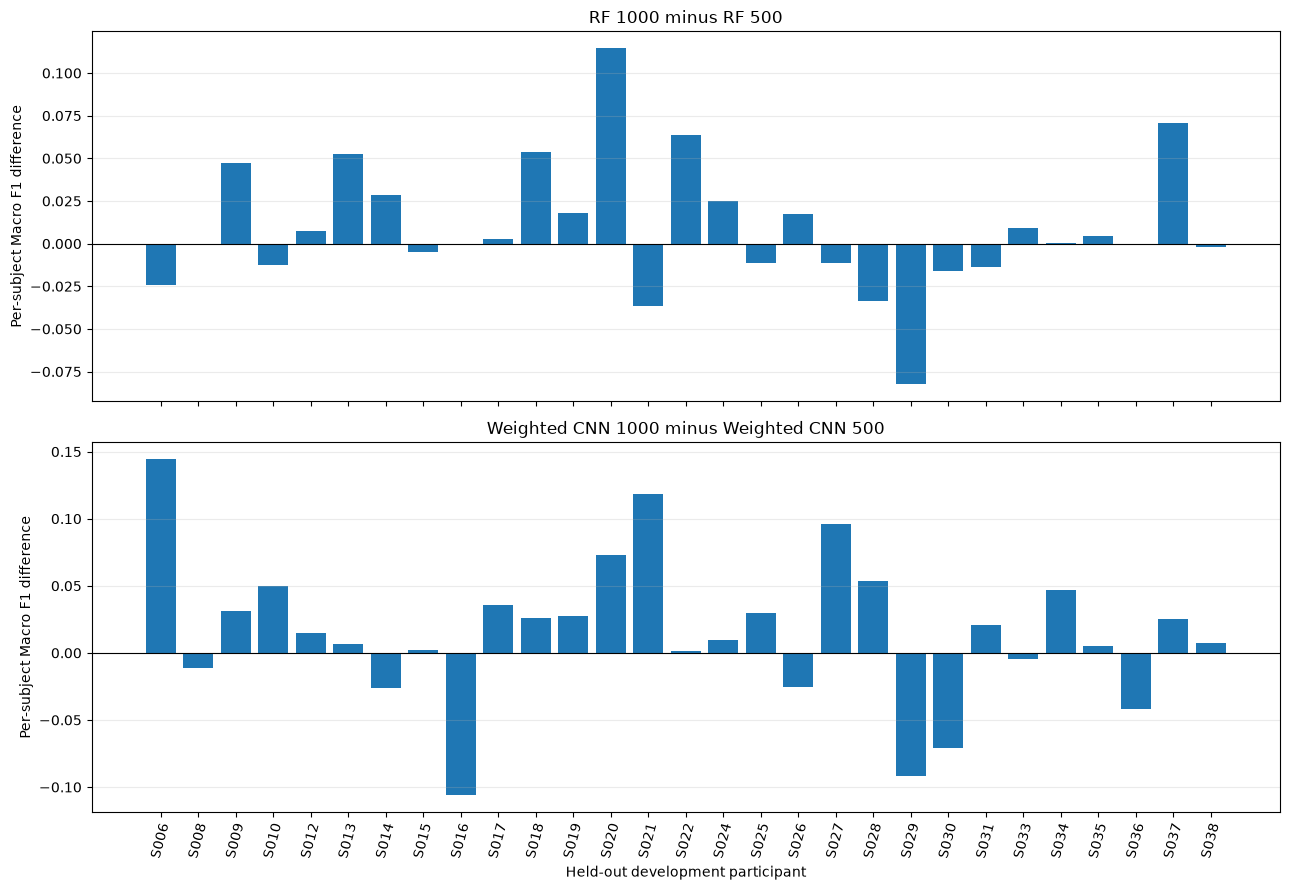

In [7]:
# =============== 07. Inspect Paired Participant-Level Changes ================

# ---------------------------- Nested Model Pairs -----------------------------
comparisons = [
    ("RF 1000", "RF 500"),
    ("Weighted CNN 1000", "Weighted CNN 500"),
]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, (larger, smaller) in zip(axes, comparisons):
    paired, difference = compare_models_by_subject(
        subject_results, model_a=larger, model_b=smaller,
        score_column="macro_f1_fixed_task",
    )
    display(pd.DataFrame([difference]).round(4))
    ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{larger} minus {smaller}",
           ylabel="Per-subject Macro F1 difference")
    ax.grid(axis="y", alpha=0.25)

axes[-1].tick_params(axis="x", rotation=75)
axes[-1].set_xlabel("Held-out development participant")
fig.tight_layout()
plt.show()


**08. Scientific Quality Gate and Limitations**

Verify nested Train windows, matched held-out source rows, participant separation and reserved Test exclusion. Three Development folds under one training configuration do not establish external generalisation or a universal effect of increasing training data.

In [8]:
# =============== 08. Matched Nested-CV Scientific Quality Gate ===============

# ------------------ Original Cap-500 Source Row Identities -------------------
original_rows = set(np.flatnonzero(metadata["in_base_500"].to_numpy()))

# ------------------ Reserved Test and Development Coverage -------------------
assert not (set(subject_results["subject_id"]) & RESERVED_TEST)

assert set(subject_results["subject_id"]) == set(DEVELOPMENT_SUBJECTS)

# ----------------------- Fold and Participant Results ------------------------
assert len(fold_results) == 4 * FOLDS

assert len(subject_results) == 4 * len(DEVELOPMENT_SUBJECTS)

# ----------------- Original Source-Row Prediction Alignment ------------------
assert len(prediction_records) == 4 * len(original_rows)

for model, table in prediction_records.groupby("model"):
    assert set(table["source_row"]) == original_rows  # Require identical held-out source rows for each model.
    assert table["source_row"].is_unique

# -------------------- Metric Checks and Research Boundary --------------------
assert fold_results["macro_f1"].between(0, 1).all()

print("Matched nested training-size grouped CV: PASSED")

print("Original protected Test subjects loaded or scored: NO")

print("Independent full-dataset benchmark: NOT ESTABLISHED")


Matched nested training-size grouped CV: PASSED
Original protected Test subjects loaded or scored: NO
Independent full-dataset benchmark: NOT ESTABLISHED
